In [1]:
from pathlib import Path
import sys
import numpy as np

import torch
import pandas as pd
import tifffile
from torch.utils.data import Dataset, DataLoader
from torch.utils.data import WeightedRandomSampler

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models import UNet

In [2]:
from src.data import MRIDataset, build_patient_params, build_weighted_sampler, build_loaders
from src.models import UNet, build_model
from src.training import bce_dice_loss, train_one_epoch, save_checkpoint, run_experiments
from src.evaluation import (
    validate_one_epoch,
    evaluate_patients_3d,
    summarize_evaluation,
    summarize_runs
)
from src.augmentation import RandomRotation

In [3]:
pairs_df = pd.read_csv(project_root / "data" / "metadata" / "pairs.csv")
splits_df = pd.read_csv(project_root / "data" / "splits" / "splits.csv")
pairs_with_split = pairs_df.merge(
    splits_df, on="patient_id", how="left", validate="many_to_one"
)

val_df = pairs_with_split.loc[pairs_with_split["split"] == "val"].copy()
train_df = pairs_with_split.loc[pairs_with_split["split"] == "train"].copy()

print(f"Train: {len(train_df)} przekrojów, {train_df['patient_id'].nunique()} pacjentów.")
print(f"Val: {len(val_df)} przekrojów, {val_df['patient_id'].nunique()} pacjentów.")

Train: 2714 przekrojów, 77 pacjentów.
Val: 615 przekrojów, 16 pacjentów.


Hipoteza: przycięcie i przeskalowanie według percentyli 10/99 przed z-score poprawi średni walidacyjny Dice 3D po pacjentach. Porównujemy próbkowanie + z-score z próbkowaniem + percentyle + z-score. Oba warianty: stały split z splits.csv, seedy 42/43/44, 40 epok, checkpoint według najwyższego Dice 3D przed filtrem. Raportujemy pięć metryk na CPU oraz średnie i odchylenia między seedami (ddof=1). Test pozostaje odłożony.

Hiptoeza2: Dodanie BatchNorm poprawi średni walidacyjny Dice 3D przed filtrem względem U-Neta bez BN, przy identycznym preprocessingu, samplingu i budżecie treningu. Porównamy również wyniki poszczególnych seedów oraz pozostałe cztery metryki.

Hipoteza3: Losowy obrót do ±10° z prawdopodobieństwem 0,5 poprawi średni walidacyjny Dice 3D przed filtrem względem UNetBN bez augmentacji. Porównujemy seedy 42/43/44 po 40 epok przy pozostałych ustawieniach bez zmian. Augmentacja dotyczy wyłącznie treningu.

In [4]:
config = {
    "experiment_name": "unet_bn_sampling_percentile_rotation_dice3d",
    "seeds": [42, 43, 44],
    "model": "unet_bn",
    "optimizer": "adam",
    "loss": "bce_dice",
    "learning_rate": 3e-4,
    "batch_size": 4,
    "num_epochs": 40,
    "preprocessing": "patient_percentile_zscore",
    "sampling": "patient_area",
    "threshold": 0.5,
    "selection_metric": "dice_3d",
    "save_last": True,
    "percentiles": [10, 99],
    "augmentation": {
        "name": "random_rotation",
        "max_angle": 10,
        "p": 0.5,
    },
    "run_training": True,
}

In [5]:
augmentation_config = config.get("augmentation")

if augmentation_config is None:
    train_transform = None
elif augmentation_config["name"] == "random_rotation":
    train_transform = RandomRotation(
        max_angle=augmentation_config["max_angle"],
        p=augmentation_config["p"],
    )
else:
    raise ValueError("nieznana augmentacja")

In [6]:
match config["preprocessing"]:
    case "patient_channel_zscore":
        train_params = build_patient_params(train_df, project_root)
        val_params = build_patient_params(val_df, project_root)
    case "scale_255":
        train_params = None
        val_params = None
    case "patient_percentile_zscore":
        train_params = build_patient_params(
            train_df,
            project_root,
            percentiles=config["percentiles"],
        )
        val_params = build_patient_params(
            val_df,
            project_root,
            percentiles=config["percentiles"],
        )
    case _:
        raise ValueError("nieznany preprocessing")        

In [7]:
train_dataset = MRIDataset(
    train_df,
    project_root,
    patient_params=train_params,
    transform=train_transform,
)

val_dataset = MRIDataset(
    val_df,
    project_root,
    patient_params=val_params,
    transform=None,
)

print(f"Długości: {len(train_dataset)} i {len(val_dataset)}")
print(f"obraz: {train_dataset[0][0].shape}")
print(f"maska: {train_dataset[0][1].shape}")

Długości: 2714 i 615
obraz: torch.Size([3, 256, 256])
maska: torch.Size([1, 256, 256])


In [8]:
from datetime import timedelta
from time import perf_counter

started_at = perf_counter()
try:
    results_df = run_experiments(
        config, project_root, train_dataset, val_dataset
    )
finally:
    elapsed_seconds = perf_counter() - started_at
    print(f"\nCzas wykonania: {timedelta(seconds=round(elapsed_seconds))}")

results_df


Seed 42: train 679 paczki, val 154 paczki
run name:  unet_bn_sampling_percentile_rotation_dice3d_seed42

epoka:  1
train loss:  0.9489994870008751
val metrics:  {'loss': 0.9142543517477144, 'dice': 0.430656043906522, 'dice_annotated': 0.6942943522106793, 'dice_empty': 0.26649076517150394, 'dice_3d': 0.5286885289795795, 'dice_3d_filtered': 0.7373399043538137}

epoka:  2
train loss:  0.4110696236922096
val metrics:  {'loss': 0.8035274008909862, 'dice': 0.7780178127734642, 'dice_annotated': 0.6376311638850277, 'dice_empty': 0.8654353562005277, 'dice_3d': 0.6276423014106159, 'dice_3d_filtered': 0.6471304135458494}

epoka:  3
train loss:  0.28587865441839927
val metrics:  {'loss': 0.7894928130192486, 'dice': 0.7602573673899581, 'dice_annotated': 0.6464333945916871, 'dice_empty': 0.8311345646437994, 'dice_3d': 0.6428106795991799, 'dice_3d_filtered': 0.6712261340263549}

epoka:  4
train loss:  0.25746380407623976
val metrics:  {'loss': 0.7748990940126946, 'dice': 0.6836921089063815, 'dice_an

,run_name,seed,epoch,dice,dice_annotated,dice_empty,dice_3d,dice_3d_filtered
0,unet_bn_sampling_percentile_rotation_dice3d_se...,42,27,0.778934,0.771375,0.783641,0.774652,0.793675
1,unet_bn_sampling_percentile_rotation_dice3d_se...,43,34,0.715388,0.766794,0.683377,0.789502,0.798965
2,unet_bn_sampling_percentile_rotation_dice3d_se...,44,25,0.756858,0.751980,0.759894,0.761105,0.784126


In [9]:
series_summary = summarize_runs(results_df)
series_summary

,mean,std
metric,,
dice,0.750393,0.032263
dice_annotated,0.763383,0.010137
dice_empty,0.742304,0.052395
dice_3d,0.775086,0.014203
dice_3d_filtered,0.792255,0.007521


## Historyczna jednoepokowa próba integracyjna

Poniższa komórka odczytuje unet_modular_smoke_seed42, czyli wcześniejszą
próbę działania modułów po jednej epoce. Nie jest to podsumowanie pełnej
serii percentylowej. Zakończone porównanie obu serii po 40 epok znajduje
się w kolejnej sekcji i korzysta ze wszystkich seedów 42/43/44.

In [9]:
saved_results_df = pd.read_csv(
    project_root / "outputs" / "unet_modular_smoke_seed42_val_metrics.csv"
)

summarize_runs(saved_results_df)

,mean,std
metric,,
dice,0.628485,NaN
dice_annotated,0.548805,NaN
dice_empty,0.678100,NaN
dice_3d,0.479485,NaN
dice_3d_filtered,0.489090,NaN


## Zakończone porównanie: z-score i percentyle 10/99 + z-score

Obie serie korzystają z tego samego podziału pacjentów w splits.csv
(train 77/2714, val 16/615), seedów treningowych 42/43/44 i 40 epok.
Użyto U-Neta, Adama z lr=3e-4, paczek po 4, BCE + średniego soft Dice
po przekrojach (wagi 1/1, eps=1e-5), próbkowania patient_area i braku augmentacji.
Checkpoint wybierano według najwyższego walidacyjnego Dice 3D przed
filtrowaniem; przy remisie zachowywano wcześniejszą epokę.
Próg to sigmoid(logits) > 0.5, a filtr zachowuje największą składową 3D
z sąsiedztwem 6. Raporty poniżej pochodzą z oceny checkpointów na CPU.

Jedyna zmiana metody to dodanie globalnych percentyli 10/99 przed z-score.
Progi wyznaczamy z całego wolumenu pacjenta łącznie z kanałami i tłem;
średnie i odchylenia po transformacji liczymy osobno dla kanałów w float64.

Komórki porównania odczytują sześć istniejących raportów CSV z outputs.
Nie uruchamiają treningu. Outputs jest lokalny i ignorowany przez Git;
zapisane wydruki zachowują tabelę także bez dostępu do tych plików.
Wyniki 07–10, wybierane według dice_annotated, stanowią oddzielną serię.

In [10]:
comparison_seeds = [42, 43, 44]
comparison_run_names = {
    "Z-score": "unet_sampling_zscore_dice3d",
    "Percentyle + z-score": "unet_sampling_percentile_zscore_dice3d",
}
comparison_results = {}

for label, prefix in comparison_run_names.items():
    reports = [
        pd.read_csv(
            project_root / "outputs" / f"{prefix}_seed{seed}_val_metrics.csv"
        )
        for seed in comparison_seeds
    ]
    series_results = pd.concat(reports, ignore_index=True)
    expected_names = [f"{prefix}_seed{seed}" for seed in comparison_seeds]
    if (
        series_results["seed"].tolist() != comparison_seeds
        or series_results["run_name"].tolist() != expected_names
    ):
        raise ValueError(f"Niezgodne raporty serii: {prefix}")
    comparison_results[label] = series_results

comparison_summary = pd.concat(
    {
        label: summarize_runs(frame)
        for label, frame in comparison_results.items()
    },
    axis=1,
)
comparison_summary.round(4)

Z-score         Percentyle + z-score        
                    mean     std                 mean     std
metric                                                       
dice              0.6353  0.1347               0.6843  0.0080
dice_annotated    0.7163  0.0439               0.7380  0.0105
dice_empty        0.5849  0.1913               0.6508  0.0185
dice_3d           0.6779  0.0738               0.6959  0.0106
dice_3d_filtered  0.7239  0.0527               0.7464  0.0302

In [11]:
control_runs = comparison_results["Z-score"].set_index("seed")
percentile_runs = comparison_results["Percentyle + z-score"].set_index("seed")

paired_comparison = pd.DataFrame({
    "epoka_zscore": control_runs["epoch"],
    "epoka_percentyle": percentile_runs["epoch"],
    "dice_3d_zscore": control_runs["dice_3d"],
    "dice_3d_percentyle": percentile_runs["dice_3d"],
    "roznica_percentyle_minus_zscore": (
        percentile_runs["dice_3d"] - control_runs["dice_3d"]
    ),
}).sort_index()
paired_comparison.round(4)

,epoka_zscore,epoka_percentyle,dice_3d_zscore,dice_3d_percentyle,roznica_percentyle_minus_zscore
seed,,,,,
42,36,33,0.7160,0.7081,-0.0079
43,30,40,0.7248,0.6892,-0.0356
44,37,40,0.5928,0.6903,0.0975


### Wniosek z zakończonej serii

Średni Dice 3D przed filtrem wzrósł z 0,6779 ± 0,0738 do
0,6959 ± 0,0106, czyli o 0,0180. Po filtrze średnia wzrosła
z 0,7239 ± 0,0527 do 0,7464 ± 0,0302, czyli o 0,0225.
Są to średnie i odchylenia standardowe z próby między trzema seedami
(ddof=1), obliczone z raportów CPU.

Wzrost nie wystąpił na każdym seedzie: zmiany surowego Dice 3D wyniosły
-0,0079 / -0,0356 / +0,0975 dla 42/43/44. Średnią podnosi głównie
seed 44, na którym poprawę odnotowano u 13 z 16 pacjentów.
Wybrane epoki kontroli to 36/30/37, a percentyli 33/40/40.

Wynik wspiera wykorzystanie percentyli jako kandydata do dalszych prób,
z zastrzeżeniem trzech seedów i jednego podziału walidacyjnego używanego
również do wyboru checkpointów. Mniejszy rozrzut wybranych wyników
nie dowodzi jeszcze ogólnej stabilizacji treningu.
Czas komórki run_experiments dla serii percentylowej wyniósł 1:08:22;
przygotowanie parametrów pacjentów odbywało się wcześniej, poza pomiarem.
Test pozostaje odłożony do zamrożenia protokołu.

## Porównanie U-Neta bez BatchNorm i z BatchNorm

Oba warianty korzystają z tego samego podziału pacjentów:
train 77/2714, val 16/615, seed podziału 42.

Wspólne ustawienia: seedy treningowe 42/43/44, 40 epok,
Adam lr=3e-4, batch size 4, BCE + średni soft Dice po przekrojach,
sampling patient_area, percentyle 10/99 + z-score, brak augmentacji.

Wariant BN dodaje BatchNorm po splotach bloków DoubleConv
i wyłącza bias w tych splotach.

Checkpoint wybieramy według najwyższego walidacyjnego Dice 3D
przed filtrem; przy remisie zostaje wcześniejsza epoka.
Próg predykcji wynosi >0.5. Filtr zachowuje największą składową
3D przy sąsiedztwie 6.

Poniższe tabele odczytują zapisane raporty CPU.
Odchylenia między seedami liczymy z ddof=1.

In [12]:
bn_seeds = [42, 43, 44]

bn_prefixes = {
    "Bez BN": "unet_sampling_percentile_zscore_dice3d",
    "Z BN": "unet_bn_sampling_percentile_zscore_dice3d",
}

bn_results = {}

for label, prefix in bn_prefixes.items():
    reports = [
        pd.read_csv(
            project_root / "outputs"
            / f"{prefix}_seed{seed}_val_metrics.csv"
        )
        for seed in bn_seeds
    ]

    bn_results[label] = pd.concat(reports, ignore_index=True)

bn_summary = pd.concat(
    {
        label: summarize_runs(frame)
        for label, frame in bn_results.items()
    },
    axis=1,
)

bn_summary.round(4)

Bez BN            Z BN        
                    mean     std    mean     std
metric                                          
dice              0.6843  0.0080  0.7642  0.0616
dice_annotated    0.7380  0.0105  0.7626  0.0140
dice_empty        0.6508  0.0185  0.7652  0.1022
dice_3d           0.6959  0.0106  0.7692  0.0071
dice_3d_filtered  0.7464  0.0302  0.7931  0.0146

In [13]:
without_bn = bn_results["Bez BN"].set_index("seed")
with_bn = bn_results["Z BN"].set_index("seed")

bn_paired = pd.DataFrame({
    "epoka_bez_bn": without_bn["epoch"],
    "epoka_bn": with_bn["epoch"],
    "dice_3d_bez_bn": without_bn["dice_3d"],
    "dice_3d_bn": with_bn["dice_3d"],
    "roznica_bn_minus_bez_bn": (
        with_bn["dice_3d"] - without_bn["dice_3d"]
    ),
}).sort_index()

bn_paired.round(4)

,epoka_bez_bn,epoka_bn,dice_3d_bez_bn,dice_3d_bn,roznica_bn_minus_bez_bn
seed,,,,,
42,33,29,0.7081,0.7758,0.0677
43,40,27,0.6892,0.7700,0.0808
44,40,18,0.6903,0.7617,0.0714


### Wniosek

Dodanie BatchNorm zwiększyło średni walidacyjny Dice 3D
z 0,6959 ± 0,0106 do 0,7692 ± 0,0071, czyli o 0,0733.
Po filtrowaniu wynik wzrósł z 0,7464 ± 0,0302
do 0,7931 ± 0,0146.

Surowy Dice 3D poprawił się na wszystkich trzech seedach:
o 0,0677 / 0,0808 / 0,0714 dla 42/43/44.
Wybrane epoki wariantu BN to 29/27/18.
Poprawę odnotowano u odpowiednio 15/16, 15/16 i 12/16 pacjentów.

Wyniki wspierają wykorzystanie wariantu BN w dalszych eksperymentach.
Dotyczą trzech seedów i jednego podziału walidacyjnego,
używanego również do wyboru checkpointów.

Zapisany czas serii 2:01:57 może obejmować uśpienie komputera
i nie służy do porównania szybkości wariantów.
Test pozostaje odłożony do zamrożenia protokołu.

## Porównanie agregacji Dice w funkcji straty

Porównujemy BCE + średni soft Dice po przekrojach
z BCE + soft Dice agregowanym po całej paczce.

Obie serie: UNetBN, seedy 42/43/44, 40 epok, batch size 4,
Adam lr=3e-4, sampling patient_area, percentyle 10/99 + z-score,
brak augmentacji i ten sam split pacjentów.

Checkpoint wybieramy według walidacyjnego Dice 3D przed filtrem.
Raporty pochodzą z oceny na CPU; odchylenia między seedami
liczymy z ddof=1.

In [14]:
loss_prefixes = {
    "Dice po przekrojach": "unet_bn_sampling_percentile_zscore_dice3d",
    "Dice po paczce": "unet_bn_sampling_percentile_batchdice_dice3d",
}

loss_results = {}

for label, prefix in loss_prefixes.items():
    reports = [
        pd.read_csv(
            project_root / "outputs"
            / f"{prefix}_seed{seed}_val_metrics.csv"
        )
        for seed in [42, 43, 44]
    ]

    loss_results[label] = pd.concat(reports, ignore_index=True)

loss_summary = pd.concat(
    {
        label: summarize_runs(frame)
        for label, frame in loss_results.items()
    },
    axis=1,
)

loss_summary.round(4)

Dice po przekrojach         Dice po paczce        
                                mean     std           mean     std
metric                                                             
dice                          0.7642  0.0616         0.8464  0.0160
dice_annotated                0.7626  0.0140         0.7369  0.0166
dice_empty                    0.7652  0.1022         0.9147  0.0224
dice_3d                       0.7692  0.0071         0.7708  0.0187
dice_3d_filtered              0.7931  0.0146         0.7725  0.0197

In [15]:
slice_runs = loss_results["Dice po przekrojach"].set_index("seed")
batch_runs = loss_results["Dice po paczce"].set_index("seed")

loss_paired = pd.DataFrame({
    "epoka_przekroje": slice_runs["epoch"],
    "epoka_paczka": batch_runs["epoch"],
    "dice_3d_przekroje": slice_runs["dice_3d"],
    "dice_3d_paczka": batch_runs["dice_3d"],
    "roznica_raw": (
        batch_runs["dice_3d"] - slice_runs["dice_3d"]
    ),
    "roznica_po_filtrze": (
        batch_runs["dice_3d_filtered"]
        - slice_runs["dice_3d_filtered"]
    ),
}).sort_index()

loss_paired.round(4)

,epoka_przekroje,epoka_paczka,dice_3d_przekroje,dice_3d_paczka,roznica_raw,roznica_po_filtrze
seed,,,,,,
42,29,34,0.7758,0.7751,-0.0007,-0.0178
43,27,33,0.7700,0.7871,0.0171,-0.0173
44,18,27,0.7617,0.7503,-0.0114,-0.0268


### Wniosek

Agregacja Dice po paczce zmieniła średni Dice 3D
z 0,7692 ± 0,0071 do 0,7708 ± 0,0187.
Zmiany dla seedów 42/43/44 wyniosły
−0,0007 / +0,0171 / −0,0114.
Nie uzyskano spójnej poprawy głównej metryki.

Dice 3D po filtrze spadł z 0,7931 ± 0,0146
do 0,7725 ± 0,0197, z pogorszeniem na każdym seedzie.
Dice oznaczonych przekrojów również spadł na każdym seedzie.

Nowy wariant lepiej rozpoznaje puste przekroje:
średni Dice pustych wzrósł z 0,7652 do 0,9147.
To wyjaśnia wzrost Dice wszystkich przekrojów
mimo spadku Dice przekrojów z adnotacją.

Do kolejnego eksperymentu zachowujemy BCE + Dice po przekrojach
jako bazę z UNetBN. Wariant po paczce pozostaje zapisanym
eksperymentem porównawczym. Wnioski dotyczą trzech seedów
na jednym podziale walidacyjnym; test pozostaje odłożony.

Obraz: torch.Size([3, 256, 256]) → torch.Size([3, 256, 256])
Maska: torch.Size([1, 256, 256]) → torch.Size([1, 256, 256])


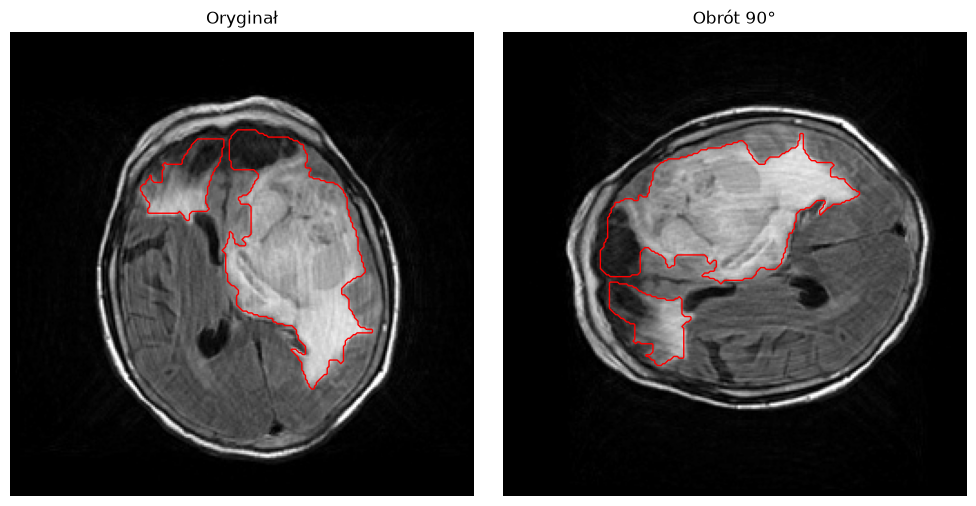

In [16]:
import matplotlib.pyplot as plt

# Wybieramy przekrój treningowy z dużą maską, łatwą do obejrzenia.
position = int(
    train_dataset.pairs_df["foreground_pixels"].to_numpy().argmax()
)
sample_image, sample_mask = train_dataset[position]

rotated_image = torch.rot90(sample_image, k=1, dims=(-2, -1))
rotated_mask = torch.rot90(sample_mask, k=1, dims=(-2, -1))

print("Obraz:", sample_image.shape, "→", rotated_image.shape)
print("Maska:", sample_mask.shape, "→", rotated_mask.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

examples = [
    (sample_image, sample_mask, "Oryginał"),
    (rotated_image, rotated_mask, "Obrót 90°"),
]

for ax, (image, mask, title) in zip(axes, examples):
    ax.imshow(image[1].numpy(), cmap="gray")  # kanał FLAIR
    ax.contour(
        mask[0].numpy(),
        levels=[0.5],
        colors="red",
        linewidths=1,
    )
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
from scipy import ndimage

row = train_dataset.pairs_df.iloc[position]

preview_image = (
    tifffile.imread(project_root / row["image_path"])
    .astype(np.float32) / 255
)
preview_mask = (
    tifffile.imread(project_root / row["mask_path"]) > 0
).astype(np.float32)

angle = 10

image_rot10 = ndimage.rotate(
    preview_image,
    angle,
    axes=(0, 1),
    reshape=False,
    order=1,
    mode="constant",
    cval=0,
    prefilter=False,
)

mask_rot10 = ndimage.rotate(
    preview_mask,
    angle,
    axes=(0, 1),
    reshape=False,
    order=0,
    mode="constant",
    cval=0,
    prefilter=False,
)

print("Obraz:", image_rot10.shape)
print("Maska:", mask_rot10.shape)
print("Wartości maski:", np.unique(mask_rot10))

Obraz: (256, 256, 3)
Maska: (256, 256)
Wartości maski: [0. 1.]


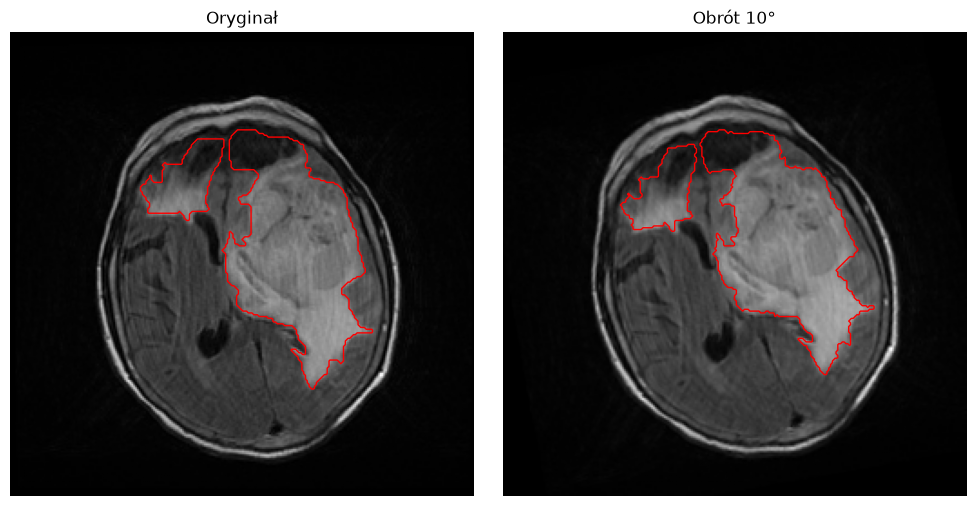

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

examples = [
    (preview_image, preview_mask, "Oryginał"),
    (image_rot10, mask_rot10, "Obrót 10°"),
]

for ax, (image, mask, title) in zip(axes, examples):
    ax.imshow(image[:, :, 1], cmap="gray")
    ax.contour(mask, levels=[0.5], colors="red", linewidths=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()